# Predicting Monthly Employment Earnings Among Young Rwandans

**Machine Learning Assignment, Task 1: Regression Models**
African Leadership University (ALU), BSc Software Engineering

## 1. Introduction

### Mission
> To create technology-driven financial and employment solutions that enable African youth to access income opportunities, build economic resilience, and transition into sustainable livelihoods.

In short: *to create technology solutions that support businesses and young people.*

### Problem statement
Young people entering the labour market often have limited information about the income they can expect from employment. Earnings vary with age, gender, education, occupation, industry, work experience, working hours, employment conditions and whether the employer is in the formal or informal sector.

This notebook builds a machine learning model that **predicts the estimated monthly cash earnings (in Rwandan francs, RWF) of a young employed person in Rwanda** from their demographic, educational and employment characteristics.

### Use case and intended users
The model turns labour-market survey data into an income estimate that could support:
- young job seekers making career and employment decisions;
- employment-support organisations advising young people;
- workforce-development organisations analysing income patterns;
- organisations building technology-driven employment and financial solutions.

The model is **not** a guarantee of anyone's future salary. It describes what similar young employees in the survey reported earning.

### Prediction objective
The dependent variable is `cash`, defined by the National Institute of Statistics of Rwanda (NISR) as *monthly income in cash for employees*, measured in RWF. It is continuous and numerical, so this is a **regression** problem:

$$Y = f(X_1, X_2, \dots, X_n)$$

where $Y$ is the predicted monthly cash earnings in RWF and $X_1 \dots X_n$ describe the person and their job.

### Connection to the mission
This project addresses the *income opportunity* part of the mission. Giving a young person a data-based estimate of what people with a similar profile earn supports employment planning and economic decision-making. The same trained pipeline is saved so that a later API and mobile application can serve these estimates to young people directly.

### Dataset source and attribution
| Item | Detail |
|---|---|
| Dataset | Rwanda Labour Force Survey 2025 (LFS 2025) |
| Data producer | National Institute of Statistics of Rwanda (NISR). Official catalogue: https://microdata.statistics.gov.rw/index.php/catalog/125 |
| File used | `RW_LFS2025_3.csv`, the microdata file downloaded directly from the NISR website |

The file contains 100,852 individual-level observations and 207 original survey variables, collected through Computer-Assisted Personal Interviewing (CAPI) in February, May, August and November 2025. It covers demographic, education, employment, occupational and labour-market information.

A processed copy of the same survey, published on Hugging Face by Electric Sheep Africa, was examined first. It has the same number of rows, but its content differs from the NISR file for a large share of rows on the columns compared, so this notebook uses the official NISR file only, and every result below comes from it.

This is real survey data, not a synthetic or tutorial dataset. The numeric income target exists for **employees only**; this is not a freelancer-income dataset.

## 2. Import libraries
I install anything that is missing (Colab already has these) and then import what I need. `RANDOM_STATE` is used everywhere so the results can be repeated.

In [1]:
import sys, subprocess, importlib

def ensure_installed(pip_name, module_name=None):
    """Install a package only if it cannot be imported (useful on a fresh Colab runtime)."""
    try:
        importlib.import_module(module_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, module_name in [("pandas", None), ("numpy", None), ("matplotlib", None),
                              ("seaborn", None), ("scikit-learn", "sklearn"), ("joblib", None)]:
    ensure_installed(pip_name, module_name)

In [2]:
import copy
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42                      # one seed used for every random operation
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## 3. Load the dataset
The notebook looks for `RW_LFS2025.csv` in the current folder, then in `/content` (where Colab puts uploads) and then in Google Drive. If it is not found and the notebook is running in Colab, an upload box opens, so you can also just upload the file.

In [3]:
CSV_NAME = "RW_LFS2025.csv"
candidate_paths = [Path(CSV_NAME), Path("/content") / CSV_NAME, Path("/content/drive/MyDrive") / CSV_NAME]
csv_path = next((p for p in candidate_paths if p.exists()), None)

if csv_path is None:
    try:
        from google.colab import files          # only available inside Google Colab
        print(f"Please upload {CSV_NAME}")
        files.upload()
        csv_path = Path(CSV_NAME)
    except ImportError:
        raise FileNotFoundError(f"{CSV_NAME} not found. Place it next to this notebook.")

df_raw = pd.read_csv(csv_path, low_memory=False)
print("Loaded from:", csv_path)
print("Dataset shape (rows, columns):", df_raw.shape)

Loaded from: RW_LFS2025.csv
Dataset shape (rows, columns): (100852, 207)


### Validate and tidy the file
Before anything else I do three things, so the rest of the notebook works with clean data.

1. **Check the file.** The columns I need must be there, otherwise the notebook stops. If the shape is not the full NISR file (100,852 rows and 207 columns) it prints a warning, because the numbers I quote in the text come from the full file.
2. **Tidy the text.** The NISR file has upper-case column names and some labels with extra spaces at the front (for example `" Elementary_occupations"`). I lower-case the names and strip the spaces so the same job does not end up as two categories.
3. **Limit on income.** Any monthly `cash` above 10,000,000 RWF (about 250 times the median) is treated as a probable typing error and set to missing, so the filter in section 6 leaves it out. It is not turned into zero. In the full file two records are affected, 34,000,000 and 41,800,000 RWF, and the next highest income is 5,000,000, so every other high income stays. Both values fall in the survey's open band "1,000,000 RWF and above", so the band cannot confirm them, and both look like an extra digit. I cannot prove that, but a single value this size adds more than 100 billion to the MSE, which is more than the whole error of the models, and it would decide every comparison. In the CSV these values are stored like `3.40e+07`, which is why a search for `34000000` finds nothing. If your copy of the file has no values above the limit, nothing changes.

In [4]:
EXPECTED_SHAPE = (100852, 207)
REQUIRED_COLUMNS = ["a04", "a01", "b02a", "indd01", "main_sect", "usual_h", "d24", "d24b",
                    "prod_unit", "d08", "d05", "cash"]

df_raw.columns = df_raw.columns.str.lower()                  # A04 -> a04, Prod_unit -> prod_unit, ...
missing_columns = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"Required columns not found: {missing_columns}. Please check the file.")
if df_raw.shape != EXPECTED_SHAPE:
    print(f"WARNING: this file has shape {df_raw.shape}, not the complete NISR file {EXPECTED_SHAPE}. "
          "The notebook will still run, but the numbers quoted in the text refer to the complete file.")

text_columns = df_raw.select_dtypes(exclude="number").columns
for column in text_columns:
    df_raw[column] = df_raw[column].str.strip()              # remove stray leading/trailing spaces

# Plausibility limit on monthly cash income (see the explanation above)
MAX_PLAUSIBLE_MONTHLY_CASH = 10_000_000
too_large = df_raw["cash"] > MAX_PLAUSIBLE_MONTHLY_CASH
print("Monthly cash values above 10,000,000 RWF set to missing:", int(too_large.sum()))
if too_large.any():
    print(df_raw.loc[too_large, ["cash", "a04", "d05", "indd01", "intcash"]].to_string())
df_raw.loc[too_large, "cash"] = np.nan

print("File shape:", df_raw.shape)
print("Occupation labels after cleaning:", sorted(df_raw["indd01"].dropna().unique()))

Monthly cash values above 10,000,000 RWF set to missing: 2
               cash  a04       d05                     indd01                  intcash
13287 41,800,000.00   48  Employee  Service_and_sales_workers  1,000,000 RWF and above
76349 34,000,000.00   29  Employee                   Managers  1,000,000 RWF and above
File shape: (100852, 207)
Occupation labels after cleaning: ['Clerical_support_workers', 'Craft_and_related_trades_workers', 'Elementary_occupations', 'Managers', 'Plant_and_machine_operators_and_assemblers', 'Professionals', 'Service_and_sales_workers', 'Skilled_agricultural,_forestry_and_fishery workers', 'Technicians_and_associate_professionals']


In [5]:
# The file has 219 columns, so the preview shows the columns relevant to this project only.
KEY_COLUMNS = ["a04", "a01", "b02a", "indd01", "main_sect", "usual_h", "d24", "d24b",
               "prod_unit", "d08", "d05", "cash"]
df_raw[KEY_COLUMNS].head()

,a04,a01,b02a,indd01,main_sect,usual_h,d24,d24b,prod_unit,d08,d05,cash
0,46,Male,Primary education,Service_and_sales_workers,Services,66.00,26.00,12.00,Informal Sector,NaN,Employee,"90,000.00"
1,45,Female,Primary education,Service_and_sales_workers,Services,77.00,3.00,12.00,Informal Sector,NaN,Own account worker,NaN
2,20,Female,Upper secondary education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,19,Male,Upper secondary education,Service_and_sales_workers,Services,77.00,1.00,7.00,Informal Sector,NaN,Contributing family worker,NaN
4,16,Female,Lower secondary education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# All 219 column names, printed compactly (12 per line)
names = df_raw.columns.tolist()
for i in range(0, len(names), 12):
    print(", ".join(names[i:i + 12]))

psu_no, qh_no, hhid, province, code_ur, code_dis, lfs_strata, lfs_year, weight2, a01, a02, a03m
a03y, a04, a05, a06, a07, a08, a09, a10, a11, a12, a13, a14a
a14b, a15, a16y, a17a, a17b, a19, a20, b01, b02a, b02b, b07, b08
b09, b10, b13, b13b, b14, b15, c01, c02, c02a, c03, c05, c06
c07, c08, c09, c09a, c10, c10a, c11a, c11b, c12a, c12b, c13a, c13b
c14, c15, c16, c17, c18, c19, c19a, c20, c20a, c21, c22, c23
c24, c25, c26, d03a, d04, d05, d05a, d05a1, d06, d07, d08, d08a
d09a, d10, d10a, d10b, d10c, d10d, d10_e, d12_1, d12_1a, d13_1, d14_1, d14_1a
d17_1, d18a, d18a_other, d20, d21, d21a, d23, d23a, d23b, d24, d24b, d25a
d25b, ds07, ds08, ds09, ds09aa, ds09aaa, ds09_a, ds09_b, ds09_c, ds09_d, ds10a, f01a
f01b, f02, f05, g01, g01a, g02, g02a, g03, g03a, g04, g04a, g05
g05a, g06, g06a, g07, g07a, h01, h02, h03, h05, h06, h09, h10
indd01, indd03, en01, en01_others, status1, indb05, wap16, employed16, ur1, lfpr, sub, tru
plf, youth, young, luu, disable, discourage, willing, migrant, neetyout

In [7]:
# Data types: a summary for the whole file and the exact types of the columns we care about
print(df_raw.dtypes.astype(str).value_counts().to_string())
print()
print(df_raw[KEY_COLUMNS].dtypes.astype(str).to_string())

str        140
float64     60
int64        7

a04            int64
a01              str
b02a             str
indd01           str
main_sect        str
usual_h      float64
d24          float64
d24b         float64
prod_unit        str
d08              str
d05              str
cash         float64


In [8]:
# Basic descriptive statistics for the numerical key columns
df_raw[["a04", "usual_h", "d24", "d24b", "cash"]].describe()

,a04,usual_h,d24,d24b,cash
count,"100,852.00","34,712.00","34,712.00","34,712.00","22,393.00"
mean,25.33,35.11,12.67,9.69,"77,740.39"
std,19.59,18.71,11.77,3.51,"152,281.07"
min,0.00,1.00,0.00,1.00,"1,000.00"
25%,9.00,20.00,3.00,8.00,"26,000.00"
50%,20.00,36.00,10.00,12.00,"39,000.00"
75%,38.00,48.00,20.00,12.00,"78,000.00"
max,95.00,120.00,75.00,12.00,"5,000,000.00"


The file has 100,852 rows and 207 columns, which is the size of the official NISR release. The first rows show how the survey is laid out: the first person is an employee with a cash income, the second is an own-account worker so there is no `cash` value, and the third has no job information at all. Only working people were asked about jobs and income, so many columns are empty for everyone else. Across the whole survey `cash` is filled in for about 22,000 of the 100,852 people.

The cell above cleans the file before anything else happens (lower-case column names, spaces removed from labels, and the income limit explained above it). If you run this notebook on a different copy of the file, the counts in my text may not match yours, so check the printed shape first.

## 4. Initial data inspection
Here I check missing values, duplicates, data types, the employment categories and the age distribution, and I count how many people are left after each filter. Missing values need care because only some respondents were asked about jobs and income. The file has no person ID, so duplicates can only be found by looking for identical rows.

In [9]:
# Missing values in the key columns across the entire survey
missing_table = pd.DataFrame({
    "missing": df_raw[KEY_COLUMNS].isna().sum(),
    "missing_pct": (df_raw[KEY_COLUMNS].isna().mean() * 100).round(1),
    "unique_values": df_raw[KEY_COLUMNS].nunique(),
})
missing_table

,missing,missing_pct,unique_values
a04,0,0.00,96
a01,0,0.00,2
b02a,41350,41.00,5
indd01,66140,65.60,9
main_sect,66140,65.60,3
usual_h,66140,65.60,113
d24,66140,65.60,73
d24b,66140,65.60,12
prod_unit,66594,66.00,3
d08,84825,84.10,7


In [10]:
# Duplicate observations. This file has no person-level identifier, so only identical rows can be detected.
print("Fully duplicated rows in the whole survey:", df_raw.duplicated().sum())
young_employees = df_raw[df_raw["a04"].between(18, 35) & (df_raw["d05"] == "Employee") & df_raw["cash"].notna()]
print("Fully duplicated rows among the young employees with a cash value:", young_employees.duplicated().sum())

Fully duplicated rows in the whole survey: 247
Fully duplicated rows among the young employees with a cash value: 0


In [11]:
# Employment categories (d05) and where the target `cash` is actually recorded
d05_filled = df_raw["d05"].fillna("Not employed / not asked")
employment_summary = pd.DataFrame({
    "people": d05_filled.value_counts(),
    "with_cash_value": df_raw["cash"].notna().groupby(d05_filled).sum(),
})
employment_summary

,people,with_cash_value
d05,,
Contributing family worker,1584,85
Employee,22071,22008
Employer,722,0
Member of cooperative,19,0
Not employed / not asked,66671,300
Own account worker,9785,0


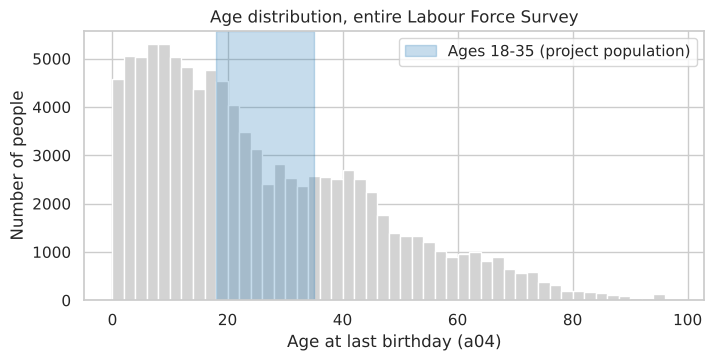

In [12]:
# Age distribution of the whole survey, with the 18-35 target range highlighted
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df_raw["a04"], bins=range(0, 100, 2), color="lightgrey", edgecolor="white")
ax.axvspan(18, 35, color="tab:blue", alpha=0.25, label="Ages 18-35 (project population)")
ax.set_xlabel("Age at last birthday (a04)")
ax.set_ylabel("Number of people")
ax.set_title("Age distribution, entire Labour Force Survey")
ax.legend()
plt.show()

In [13]:
# Number of observations remaining after each filtering stage (counts are computed, not typed in)
stage_all = df_raw
stage_age = stage_all[stage_all["a04"].between(18, 35)]
stage_employee = stage_age[stage_age["d05"] == "Employee"]
stage_cash = stage_employee[stage_employee["cash"].notna()]

filter_counts = pd.DataFrame({
    "Filtering stage": ["Entire dataset", "Aged 18-35", "Aged 18-35 and Employee", "... with a numerical cash value"],
    "Observations": [len(stage_all), len(stage_age), len(stage_employee), len(stage_cash)],
})
filter_counts

,Filtering stage,Observations
0,Entire dataset,100852
1,Aged 18-35,27867
2,Aged 18-35 and Employee,11264
3,... with a numerical cash value,11232


**Findings.**

About 66% of the survey has no job information, because those questions were only asked to people who work. So a blank here usually means "not asked", not "forgotten". Income (`cash`) only exists for employees: 22,008 of the 22,071 employees have a value, while employers, own-account workers and cooperative members have none. A few other people have a value too (85 family workers and 300 people with no employment type), but they are not employees, so the `d05` filter removes them. That confirms the project is about employee income and not freelancer income.

The file has 247 identical rows, but none of them are in our group, and without a person ID I could not tell whether they are real duplicates anyway. The filters take us from 100,852 people to 27,867 aged 18 to 35, then 11,264 employees, then 11,232 with a usable income. The other 32 employees have no usable income, so they are left out and not set to zero.

## 5. Target investigation: `cash`
`cash` is monthly cash income for employees, in RWF. Before using it I check how many values there are, how they are spread, and whether the extreme ones look believable. `d12_1a` and `d14_1a` are empty in this file and `intcash` only has income bands, so none of them can be the target. The target stays in RWF.

In [14]:
# Confirm the two tempting alternatives are unusable
print("d12_1a non-missing values:", df_raw["d12_1a"].notna().sum())
print("d14_1a non-missing values:", df_raw["d14_1a"].notna().sum())
print("intcash example values   :", df_raw["intcash"].dropna().unique()[:4].tolist())

d12_1a non-missing values: 0
d14_1a non-missing values: 0
intcash example values   : ['80,000 - 99,999 FRW', '50,000-79,999 RWF', '30,000-49,999 RWF', '100,000-199,999RWF']


In [15]:
# Summary statistics of the target for young employees (before dropping the few missing cash values)
cash_young_emp = stage_employee["cash"]
target_stats = pd.Series({
    "Valid observations": cash_young_emp.notna().sum(),
    "Missing observations": cash_young_emp.isna().sum(),
    "Minimum (RWF)": cash_young_emp.min(),
    "Maximum (RWF)": cash_young_emp.max(),
    "Mean (RWF)": cash_young_emp.mean(),
    "Median (RWF)": cash_young_emp.median(),
    "Standard deviation (RWF)": cash_young_emp.std(),
    "Zero values": (cash_young_emp == 0).sum(),
    "Skewness": cash_young_emp.skew(),
})
target_stats.to_frame("cash")

,cash
Valid observations,"11,232.00"
Missing observations,32.00
Minimum (RWF),"3,000.00"
Maximum (RWF),"5,000,000.00"
Mean (RWF),"74,877.40"
Median (RWF),"39,000.00"
Standard deviation (RWF),"132,972.41"
Zero values,0.00
Skewness,12.91


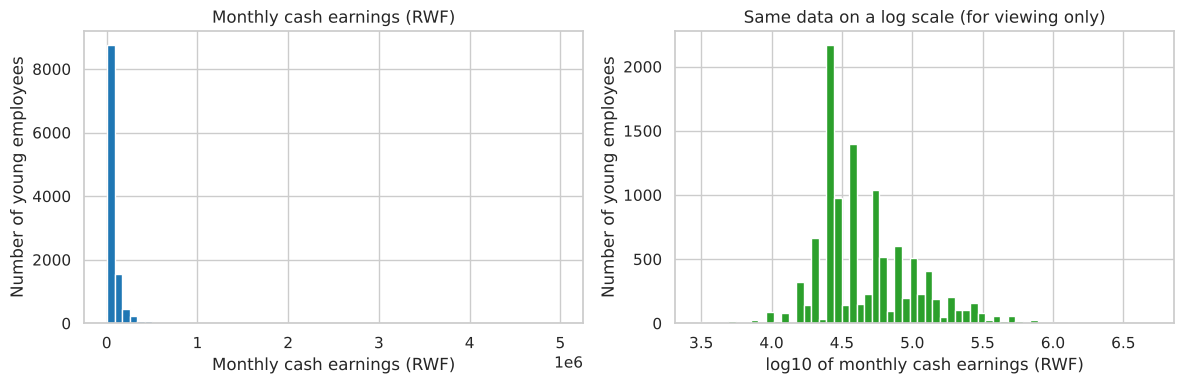

In [16]:
# Distribution of the target. The right-hand panel uses a log axis for VIEWING only; the model target stays in RWF.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cash_young_emp.dropna(), bins=60, color="tab:blue", edgecolor="white")
axes[0].set_xlabel("Monthly cash earnings (RWF)")
axes[0].set_ylabel("Number of young employees")
axes[0].set_title("Monthly cash earnings (RWF)")
axes[1].hist(np.log10(cash_young_emp.dropna()), bins=60, color="tab:green", edgecolor="white")
axes[1].set_xlabel("log10 of monthly cash earnings (RWF)")
axes[1].set_ylabel("Number of young employees")
axes[1].set_title("Same data on a log scale (for viewing only)")
plt.tight_layout()
plt.show()

In [17]:
# Investigate the high earners instead of deleting them
q1, q3 = cash_young_emp.quantile([0.25, 0.75])
iqr_upper_fence = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: {iqr_upper_fence:,.0f} RWF; observations above it: {(cash_young_emp > iqr_upper_fence).sum()}")
print()
print(cash_young_emp.quantile([0.90, 0.95, 0.99, 0.999]).rename("percentile value (RWF)").to_frame())
print()
top_earners = stage_cash.nlargest(10, "cash")[["cash", "a04", "b02a", "indd01", "main_sect", "prod_unit", "usual_h"]]
top_earners

IQR upper fence: 156,000 RWF; observations above it: 960

      percentile value (RWF)
0.90              142,880.80
0.95              250,000.00
0.99              520,000.00
1.00            1,500,000.00



,cash,a04,b02a,indd01,main_sect,prod_unit,usual_h
19407,"5,000,000.00",28,Tertiary education,Managers,Services,Formal sector,40.00
38444,"4,000,000.00",28,Tertiary education,Managers,Services,Informal Sector,40.00
830,"3,000,000.00",27,Tertiary education,Professionals,Services,Formal sector,40.00
82565,"2,310,000.00",33,Tertiary education,Professionals,Services,Formal sector,40.00
76333,"2,300,000.00",33,Tertiary education,Managers,Industry,Formal sector,48.00
57462,"2,261,000.00",32,Tertiary education,Managers,Industry,Formal sector,48.00
57475,"2,100,000.00",29,Tertiary education,Professionals,Services,Formal sector,45.00
7043,"2,000,000.00",28,Tertiary education,Professionals,Services,Formal sector,40.00
51138,"2,000,000.00",27,Upper secondary education,Technicians_and_associate_professionals,Services,Formal sector,14.00
19425,"1,950,000.00",29,Upper secondary education,Professionals,Services,Informal Sector,35.00


In [18]:
# Are high earnings plausible? Compare median pay by occupation group.
(stage_cash.groupby("indd01")["cash"].agg(["count", "median", "mean", "max"])
 .sort_values("median", ascending=False))

,count,median,mean,max
indd01,,,,
Managers,114,"186,000.00","389,989.41","5,000,000.00"
Technicians_and_associate_professionals,201,"180,000.00","255,224.49","2,000,000.00"
Clerical_support_workers,185,"125,000.00","170,736.76","900,000.00"
Professionals,856,"125,000.00","199,974.95","3,000,000.00"
Craft_and_related_trades_workers,830,"120,000.00","129,985.37","780,000.00"
Plant_and_machine_operators_and_assemblers,235,"100,000.00","140,612.77","1,040,000.00"
Service_and_sales_workers,1039,"52,000.00","75,790.27","1,350,000.00"
"Skilled_agricultural,_forestry_and_fishery workers",45,"39,000.00","45,529.26","200,000.00"
Elementary_occupations,7727,"31,200.00","41,513.19","1,040,000.00"


**What the data shows.**

Among the 11,232 young employees, monthly cash earnings go from 3,000 to 5,000,000 RWF. The median is 39,000 but the mean is about 74,900 and the skewness is 12.9, so a small number of high earners pull the average up. About 80% of people earn less than 100,000 RWF a month and only about 1% earn more than 500,000. There are 960 observations above the IQR fence of 156,000 RWF, and the 99th percentile is 520,000.

**Are the high values real?**

I looked at the ten highest. They are almost all tertiary-educated managers and professionals in services or industry, and the occupation table says the same thing: median pay is 186,000 RWF for managers and 180,000 for technicians but only 31,200 for elementary occupations. So the large values fit the jobs behind them and I did not treat them as mistakes. (The only values I removed are the ones above 10,000,000 RWF, explained in the cleaning step.)

**Decision.**

I kept the high earners and left `cash` in RWF, as the assignment asks. The cost is that MSE will be dominated by a few big earners, so I read it together with RMSE and MAE later on.

## 6. Filter the population
The model is for young employees, so I keep only people who are
1. aged 18 to 35 (`a04`),
2. classified as `Employee` (`d05`), and
3. have a valid `cash` value.

I do not fill missing income with zero. Most of the missing values belong to people who are not employees (own-account workers, employers, family workers). They were never asked the employee income question, and a zero would say they earn nothing.

In [19]:
df_model = df_raw[
    df_raw["a04"].between(18, 35)
    & (df_raw["d05"] == "Employee")
    & df_raw["cash"].notna()
].copy()

print("Final number of valid observations:", len(df_model))
print("Matches the staged count above    :", len(df_model) == len(stage_cash))

Final number of valid observations: 11232
Matches the staged count above    : True


## 7. Exploratory data analysis
I use the plots to make decisions about the model, not just to show them. Under each plot I write what it shows, what pattern I see, and what I decided because of it. First I look at which candidate predictors are numerical and which are categorical.

In [20]:
NUMERICAL_CANDIDATES = ["a04", "usual_h", "d24", "d24b"]
CATEGORICAL_CANDIDATES = ["a01", "b02a", "indd01", "main_sect", "prod_unit", "d08"]

print("Numerical candidates:")
print(df_model[NUMERICAL_CANDIDATES].describe().loc[["count", "min", "50%", "max"]].to_string())
print()
print("Categorical candidates (missing values and number of categories):")
pd.DataFrame({"missing": df_model[CATEGORICAL_CANDIDATES].isna().sum(),
              "number of categories": df_model[CATEGORICAL_CANDIDATES].nunique()})

Numerical candidates:
            a04   usual_h       d24      d24b
count 11,232.00 11,232.00 11,232.00 11,232.00
min       18.00      1.00      0.00      1.00
50%       26.00     36.00      5.00     12.00
max       35.00    120.00     22.00     12.00

Categorical candidates (missing values and number of categories):


,missing,number of categories
a01,0,2
b02a,320,5
indd01,0,9
main_sect,0,3
prod_unit,0,3
d08,3647,7


### Visualisation 1: Correlation heatmap

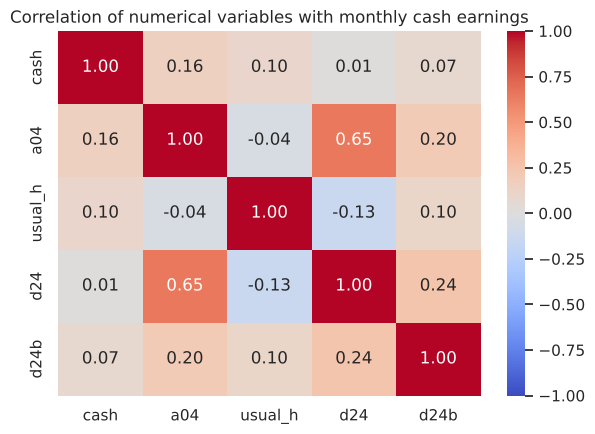

Correlation with cash (strongest first):
a04       0.15
usual_h   0.10
d24b      0.07
d24       0.01


In [21]:
numeric_for_corr = ["cash"] + NUMERICAL_CANDIDATES
corr_matrix = df_model[numeric_for_corr].corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of numerical variables with monthly cash earnings")
plt.tight_layout()
plt.show()

print("Correlation with cash (strongest first):")
print(corr_matrix["cash"].drop("cash").sort_values(key=abs, ascending=False).round(3).to_string())

**What the plot shows and what it means.**

The heatmap shows how each numerical variable moves with monthly earnings. Age has the strongest link with `cash` (about 0.15), then usual hours (0.10) and months worked per year (0.07). Work experience is almost unrelated to earnings (0.01), even though it is strongly linked to age (0.65), which is the only pair of predictors that is highly correlated.

Because every correlation with `cash` is weak, I expect the numbers alone to predict income poorly, and I expect the categorical features (education, occupation, sector) to matter more. The age and experience pair is below 0.8, so I kept all four numerical features instead of dropping one. SGDRegressor's penalty and the tree models can cope with the overlap.

### Visualisation 2: Distributions of the important numerical variables

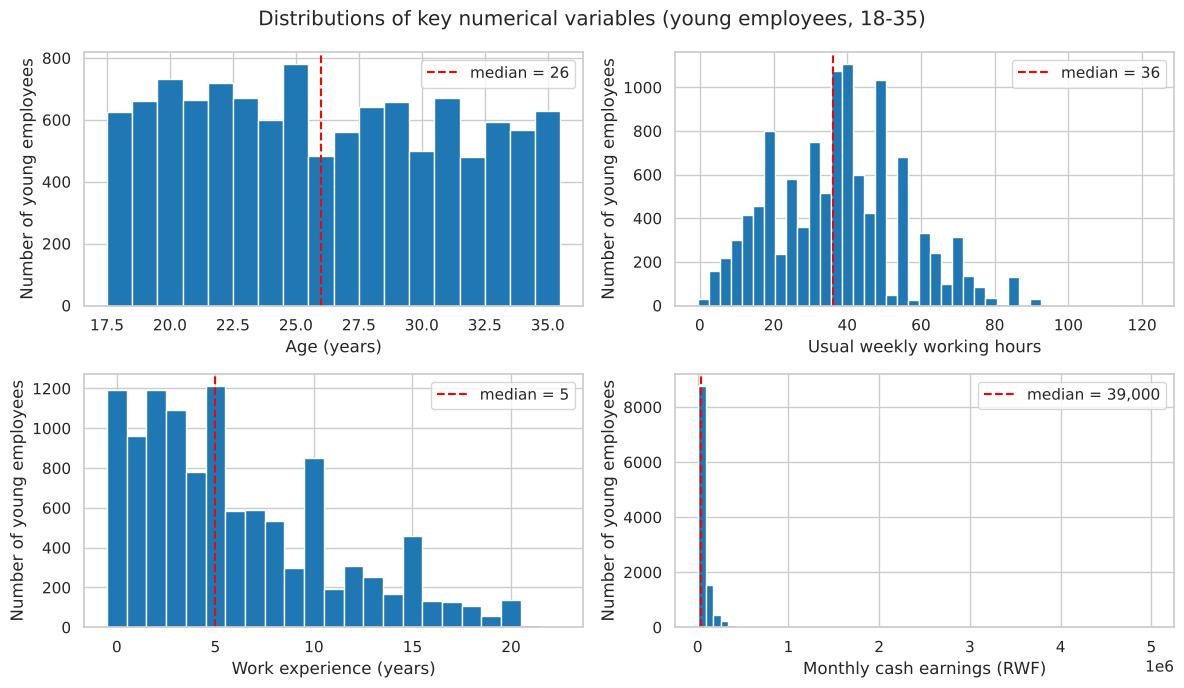

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_specs = [("a04", "Age (years)", np.arange(17.5, 36.5, 1)),
              ("usual_h", "Usual weekly working hours", np.arange(-0.5, 125.5, 3)),
              ("d24", "Work experience (years)", np.arange(-0.5, 23.5, 1)),
              ("cash", "Monthly cash earnings (RWF)", 60)]
for ax, (col, label, bins) in zip(axes.ravel(), plot_specs):
    ax.hist(df_model[col], bins=bins, color="tab:blue", edgecolor="white")
    ax.axvline(df_model[col].median(), color="red", linestyle="--", label=f"median = {df_model[col].median():,.0f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of young employees")
    ax.legend()
plt.suptitle("Distributions of key numerical variables (young employees, 18-35)")
plt.tight_layout()
plt.show()

**What the plots show.**

Ages are spread fairly evenly from 18 to 35 (median 26). Usual working hours have a median of 36 a week, with spikes at round numbers such as 36 and 40 hours (about 9 to 10% of people each) and a long tail up to 120 hours. Work experience is skewed to the right with a median of 5 years and spikes at 5, 10, 15 and 20, which looks like people rounding their answers. Earnings are very skewed: the median is 39,000 RWF and almost everyone is in the first bar of the histogram.

**Decisions.**

The four numbers are on very different scales (age 18 to 35, hours up to 120), so I standardise them, which matters mostly for the SGD model. I leave `cash` as it is because the assignment scores MSE in RWF, which means a few large earners will still have a big influence on the results. Tree models do not care about scaling, so the same preprocessing is fine for them.

### Visualisation 3: Earnings by education, sector and occupation

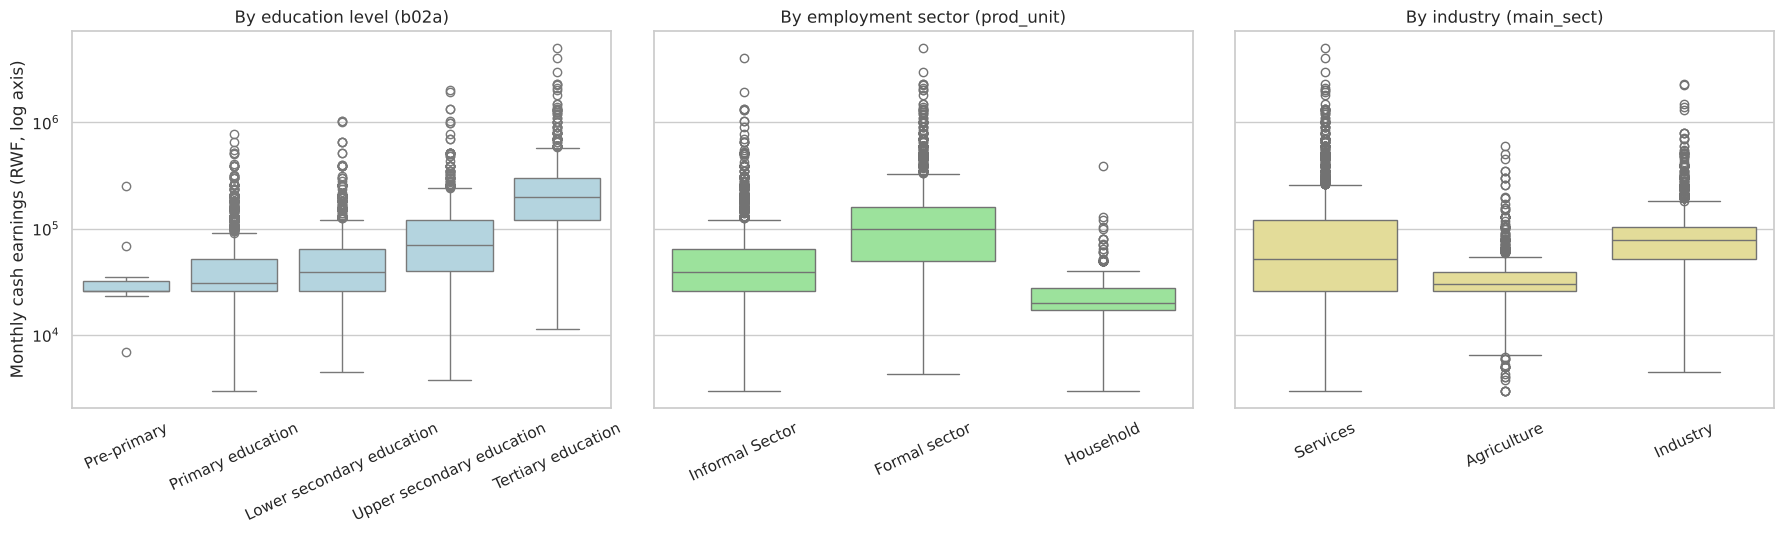

                           count     median
b02a                                       
Pre-primary                   12  26,000.00
Primary education           6178  31,200.00
Lower secondary education   2120  39,000.00
Upper secondary education   1665  70,000.00
Tertiary education           937 200,000.00 

                 count     median
prod_unit                        
Household          950  20,000.00
Informal Sector   7806  39,000.00
Formal sector     2476 100,000.00 

             count    median
main_sect                   
Agriculture   4468 30,000.00
Services      4279 52,000.00
Industry      2485 78,000.00 

        count    median
a01                    
Female   5078 31,200.00
Male     6154 52,000.00 



In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
order_edu = ["Pre-primary", "Primary education", "Lower secondary education",
             "Upper secondary education", "Tertiary education"]
sns.boxplot(data=df_model, x="b02a", y="cash", order=order_edu, ax=axes[0], color="lightblue")
axes[0].set_title("By education level (b02a)")
sns.boxplot(data=df_model, x="prod_unit", y="cash", ax=axes[1], color="lightgreen")
axes[1].set_title("By employment sector (prod_unit)")
sns.boxplot(data=df_model, x="main_sect", y="cash", ax=axes[2], color="khaki")
axes[2].set_title("By industry (main_sect)")
for ax in axes:
    ax.set_yscale("log")                      # log axis for viewing only
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Monthly cash earnings (RWF, log axis)")
plt.tight_layout()
plt.show()

# The medians behind the boxes (plus gender, which is also a retained feature)
for col in ["b02a", "prod_unit", "main_sect", "a01"]:
    print(df_model.groupby(col)["cash"].agg(["count", "median"]).sort_values("median").round(0).to_string(), "\n")

**What the plots show.**

Median pay goes up with education: 31,200 RWF for primary, 70,000 for upper secondary and 200,000 for tertiary. Formal sector employees have a median of 100,000 RWF against 39,000 in the informal sector and 20,000 in households, and industry (78,000) and services (52,000) pay more than agriculture (30,000). The printed medians also show men at 52,000 and women at 31,200 RWF, which I did not adjust for job or hours. The boxes overlap a lot, so these are tendencies and not strict rules.

**Decisions.**

Education and sector separate earnings more clearly than any numerical variable, so I keep all of them and one-hot encode them. The gender gap is just what the survey shows and I do not say it is a cause. The model will pick it up because gender is a feature, so its predictions should be read the same way.

### Visualisation 4: Contract duration (`d08`) and its missing values
`d08` is missing for a big share of employees, so I check whether being missing is related to income before I decide what to do with it.

                           count     median       mean
d08_label                                             
Daily contract/Agreement    6348  39,000.00  55,413.00
Not recorded                3647  50,000.00  97,179.00
One to less than 3 months    362  39,000.00  69,947.00
Less than one month          264  48,400.00  77,139.00
12 to less than 24 months    256 100,000.00 153,847.00
6 to less than 12 months     132  81,000.00 134,721.00
2 years or more              128  76,500.00 165,050.00
3 to less than 6 months       95  80,000.00 114,444.00


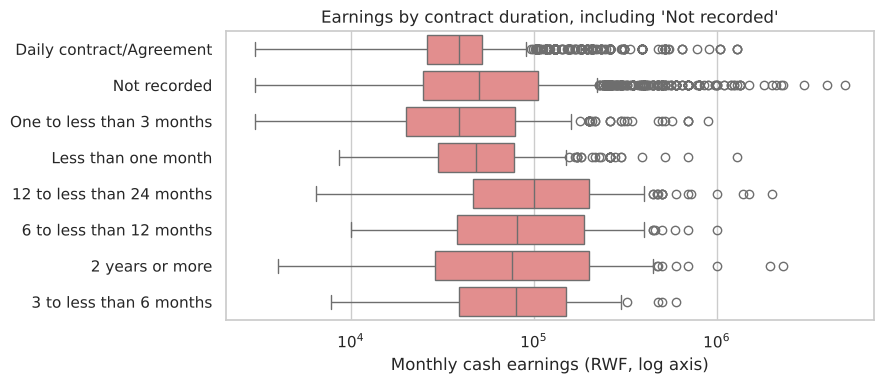

In [24]:
d08_view = df_model.assign(d08_label=df_model["d08"].fillna("Not recorded"))
d08_summary = (d08_view.groupby("d08_label")["cash"].agg(["count", "median", "mean"])
               .sort_values("count", ascending=False))
print(d08_summary.round(0).to_string())

plt.figure(figsize=(9, 4))
order = d08_summary.index.tolist()
sns.boxplot(data=d08_view, y="d08_label", x="cash", order=order, color="lightcoral")
plt.xscale("log")
plt.xlabel("Monthly cash earnings (RWF, log axis)")
plt.ylabel("")
plt.title("Earnings by contract duration, including 'Not recorded'")
plt.tight_layout()
plt.show()

**What the plot shows.**

Contract duration is missing for 3,647 of the 11,232 employees (about 32%). They are not a random group: their median pay is 50,000 RWF, higher than the 39,000 of people on daily contracts. Longer contracts pay more, for example a median of 100,000 RWF for 12 to 24 months, but several of those groups are small (under 260 people each).

**Decision.**

Dropping a third of the rows would bias the sample, and guessing a value would hide this difference. So I keep the rows and treat a missing contract as its own category called `Missing`.

## 8. Feature engineering and selection

### Retained and dropped columns

In [25]:
retained = pd.DataFrame([
    ("a04", "numerical", "Age", "Retained. Age is a basic driver of pay and has no missing values."),
    ("usual_h", "numerical", "Usual working hours", "Retained. Hours worked directly affect monthly pay."),
    ("d24", "numerical", "Work experience (years)", "Retained. Experience is a standard earnings factor."),
    ("d24b", "numerical", "Months worked per year", "Retained. Seasonal or part-year work reduces monthly cash income."),
    ("a01", "categorical", "Gender", "Retained. Allows the model to reflect gender differences observed in the data."),
    ("b02a", "categorical", "Education level", "Retained. Missing values are filled with a 'Missing' category."),
    ("indd01", "categorical", "Occupation group", "Retained. Strong visible differences in pay between groups."),
    ("main_sect", "categorical", "Industry (agriculture, industry, services)", "Retained."),
    ("prod_unit", "categorical", "Formal / informal / household sector", "Retained. Has variation among employees (checked above)."),
    ("d08", "categorical", "Contract duration", "Retained. Heavy missingness is treated as its own 'Missing' category, not guessed."),
], columns=["column", "type", "meaning", "decision"])
retained

,column,type,meaning,decision
0,a04,numerical,Age,Retained. Age is a basic driver of pay and has...
1,usual_h,numerical,Usual working hours,Retained. Hours worked directly affect monthly...
2,d24,numerical,Work experience (years),Retained. Experience is a standard earnings fa...
3,d24b,numerical,Months worked per year,Retained. Seasonal or part-year work reduces m...
4,a01,categorical,Gender,Retained. Allows the model to reflect gender d...
5,b02a,categorical,Education level,Retained. Missing values are filled with a 'Mi...
6,indd01,categorical,Occupation group,Retained. Strong visible differences in pay be...
7,main_sect,categorical,"Industry (agriculture, industry, services)",Retained.
8,prod_unit,categorical,Formal / informal / household sector,Retained. Has variation among employees (check...
9,d08,categorical,Contract duration,Retained. Heavy missingness is treated as its ...


In [26]:
dropped = pd.DataFrame([
    ("cash", "Target variable, cannot be a predictor."),
    ("intcash", "Income band derived from the target; including it would leak the answer."),
    ("d05", "Used for filtering. Every remaining row is 'Employee', so it has no variation."),
    ("d10", f"Very limited availability ({df_model['d10'].notna().sum()} non-missing values among the {len(df_model)} modelled employees)."),
    ("d12_1a, d14_1a", "Completely empty in the NISR file."),
    ("psu_no, qh_no, hhid", "Sampling and household identifiers; they do not describe earning potential and could let a model memorise households."),
    ("province, code_ur, code_dis, lfs_strata", "Geographic and sampling-design columns. Outside the candidate pool, so left out to keep the model about personal and job characteristics; location is a possible future improvement."),
    ("attained, isco2digit, isic2digitdigit", "Overlap with b02a, indd01 and main_sect (more categories or more missing values). Kept out for simplicity."),
    ("weight2", "Survey weight, not a characteristic of the person. Not used as a predictor."),
], columns=["column(s)", "reason dropped"])
dropped

,column(s),reason dropped
0,cash,"Target variable, cannot be a predictor."
1,intcash,Income band derived from the target; including...
2,d05,Used for filtering. Every remaining row is 'Em...
3,d10,Very limited availability (892 non-missing val...
4,"d12_1a, d14_1a",Completely empty in the NISR file.
5,"psu_no, qh_no, hhid",Sampling and household identifiers; they do no...
6,"province, code_ur, code_dis, lfs_strata",Geographic and sampling-design columns. Outsid...
7,"attained, isco2digit, isic2digitdigit","Overlap with b02a, indd01 and main_sect (more ..."
8,weight2,"Survey weight, not a characteristic of the per..."


In [27]:
FEATURES_NUMERICAL = ["a04", "usual_h", "d24", "d24b"]
FEATURES_CATEGORICAL = ["a01", "b02a", "indd01", "main_sect", "prod_unit", "d08"]
FEATURES = FEATURES_NUMERICAL + FEATURES_CATEGORICAL
TARGET = "cash"

print(f"Number of features: {len(FEATURES)} ({len(FEATURES_NUMERICAL)} numerical, {len(FEATURES_CATEGORICAL)} categorical)")

# Final modelling table: only the features and the target
X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()
print("Missing values per feature:")
print(X.isna().sum()[X.isna().sum() > 0].to_string())

Number of features: 10 (4 numerical, 6 categorical)
Missing values per feature:
b02a     320
d08     3647


**Summary of the decisions.**

I use ten features, four numerical (`a04`, `usual_h`, `d24`, `d24b`) and six categorical (`a01`, `b02a`, `indd01`, `main_sect`, `prod_unit`, `d08`), which meets the requirement of at least eight with a mix of both types. Only two have missing values: education (320 rows) and contract duration (3,647 rows), and both get a `Missing` category. I left out the target and anything built from it (`intcash`), the empty columns, the identifiers, the location columns, and the variables that repeat what I already have (see the table above). `d10` has too few values to use. None of the kept features is calculated from `cash`, so nothing leaks from the target.

### Preprocessing design

| Step | Applied to | Technique | Reason |
|---|---|---|---|
| Missing numerical values | `a04`, `usual_h`, `d24`, `d24b` | `SimpleImputer(strategy="median")` | None are missing in this data, but the median is robust to outliers if a future user leaves a value blank. |
| Scaling | numerical features | `StandardScaler` | Puts age (about 18-35) and hours (up to 120) on the same scale. This is essential for gradient descent and harmless for trees. |
| Missing categorical values | categorical features | `SimpleImputer(strategy="constant", fill_value="Missing")` | Keeps "not recorded" as information rather than guessing an education level or contract type. |
| Encoding | categorical features | `OneHotEncoder(handle_unknown="ignore")` | Models need numbers. Unknown categories at prediction time become all zeros instead of crashing the API. |
| Combination | all | `ColumnTransformer` | One object applies the right step to the right column. |

The preprocessor is built here but **fitted only on training data** after the split in the next section.

In [28]:
def build_preprocessor():
    """Return a fresh, unfitted preprocessing object."""
    numerical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numerical", numerical_steps, FEATURES_NUMERICAL),
        ("categorical", categorical_steps, FEATURES_CATEGORICAL),
    ])

preprocessor_template = build_preprocessor()
preprocessor_template

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

## 9. Train/test split
I split the data 80/20 with a fixed seed, and I stratify by earnings group so the high and low earners are spread across both sets. All four models use the same `X_train`, `X_test`, `y_train` and `y_test`. The test set is kept for the final comparison only. Settings are chosen on validation data taken from the training set, so the test set is never used for tuning.

In [29]:

# Divide earnings into 10 quantile-based groups
earnings_groups = pd.qcut(y, q=10, labels=False, duplicates="drop")

# Split into training and testing sets while preserving earnings-group proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE,
    stratify=earnings_groups
)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

# Fit preprocessing on training data only
preprocessor = build_preprocessor().fit(X_train)
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)

print("Transformed training matrix shape:", X_train_t.shape)
print("Median cash, train vs test:", f"{y_train.median():,.0f} vs {y_test.median():,.0f} RWF")
print("Std. dev. of cash, train vs test:", f"{y_train.std():,.0f} vs {y_test.std():,.0f} RWF")
print("Largest cash value in train vs test:", f"{y_train.max():,.0f} vs {y_test.max():,.0f} RWF")


Training rows: 8985 | Testing rows: 2247
Transformed training matrix shape: (8985, 35)
Median cash, train vs test: 39,000 vs 39,000 RWF
Std. dev. of cash, train vs test: 136,155 vs 119,428 RWF
Largest cash value in train vs test: 5,000,000 vs 2,261,000 RWF


In [30]:
# Helper used for every model: MSE on a given dataset
def mse(model, X_data, y_data):
    return mean_squared_error(y_data, model.predict(X_data))

## 10. SGDRegressor (linear regression by gradient descent)
`SGDRegressor` fits the same kind of linear model as ordinary least squares, but step by step. It goes through the training rows and nudges the coefficients in the direction that lowers the squared error. One pass through the training data is one epoch.

What I tune:
- **Learning rate:** the schedule (`constant` or `invscaling`) and the starting value `eta0`. Too large and the coefficients jump around, too small and learning is slow.
- **`alpha`:** the strength of an L2 penalty that shrinks the coefficients. It helps against overfitting, but too much makes the model too simple.
- **Number of epochs:** too few and the model underfits, too many can overfit or just waste time.

To avoid touching the test set, I split the training data again into a sub-training part (80%) and a validation part (20%). Each setting is trained for up to 500 epochs with `partial_fit()` (one call is one epoch) and the validation MSE is recorded after every epoch. The preprocessor is fitted on the sub-training part only, and the setting with the lowest validation MSE is chosen.

In [31]:

# Validation split carved out of the TRAINING data only
sub_groups = earnings_groups.loc[X_train.index]

X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=sub_groups
)

# Fit preprocessing on sub-training data only
prep_sub = build_preprocessor().fit(X_sub)
X_sub_t, X_val_t = prep_sub.transform(X_sub), prep_sub.transform(X_val)

MAX_TUNING_EPOCHS = 500
search_rows = []

for schedule in ["constant", "invscaling"]:
    for eta0 in [1e-4, 1e-3, 1e-2, 5e-2]:
        for alpha in [1e-6, 1e-4, 1e-2, 1.0, 100.0]:
            sgd = SGDRegressor(
                loss="squared_error",
                penalty="l2",
                alpha=alpha,
                learning_rate=schedule,
                eta0=eta0,
                random_state=RANDOM_STATE
            )

            val_curve = []

            with warnings.catch_warnings(), np.errstate(all="ignore"):
                warnings.simplefilter("ignore")

                for epoch in range(MAX_TUNING_EPOCHS):
                    sgd.partial_fit(X_sub_t, y_sub)
                    val_curve.append(mse(sgd, X_val_t, y_val))

            val_curve = np.array(val_curve, dtype=float)
            val_curve[~np.isfinite(val_curve)] = np.inf

            search_rows.append({
                "learning_rate": schedule,
                "eta0": eta0,
                "alpha": alpha,
                "best_epoch": int(val_curve.argmin()) + 1,
                "best_validation_MSE": val_curve.min()
            })

sgd_search = pd.DataFrame(search_rows).sort_values(
    "best_validation_MSE"
).reset_index(drop=True)

pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if abs(v) < 1 else f"{v:,.0f}")
display(sgd_search.head(8))

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Best validation MSE reached at each regularisation strength (alpha):")
print(
    sgd_search.groupby("alpha")["best_validation_MSE"]
    .min()
    .rename(index=lambda a: f"{a:g}")
    .map("{:,.0f}".format)
    .to_string()
)


,learning_rate,eta0,alpha,best_epoch,best_validation_MSE
0,invscaling,0.01,1e-06,494,"19,343,083,399"
1,invscaling,0.01,0.0001,490,"19,344,697,942"
2,constant,0.001,1e-06,500,"19,348,562,019"
3,constant,0.001,0.0001,500,"19,350,240,327"
4,invscaling,0.05,1e-06,500,"19,350,471,340"
5,invscaling,0.05,0.0001,500,"19,352,157,210"
6,constant,0.0001,1e-06,500,"19,352,991,609"
7,constant,0.0001,0.0001,500,"19,354,416,254"


Best validation MSE reached at each regularisation strength (alpha):
alpha
1e-06     19,343,083,399
0.0001    19,344,697,942
0.01      19,511,498,995
1         22,561,008,816
100       24,966,450,292


In [32]:
best_sgd = sgd_search.iloc[0]
SGD_PARAMS = {"learning_rate": str(best_sgd["learning_rate"]), "eta0": float(best_sgd["eta0"]), "alpha": float(best_sgd["alpha"])}
SGD_EPOCHS = int(best_sgd["best_epoch"])
print("Chosen by validation MSE:", SGD_PARAMS, "| epochs:", SGD_EPOCHS)

Chosen by validation MSE: {'learning_rate': 'invscaling', 'eta0': 0.01, 'alpha': 1e-06} | epochs: 494


**What the search shows.**

I tried 40 combinations of schedule, `eta0` and `alpha`, each for up to 500 epochs. The best one used the `invscaling` schedule with `eta0 = 0.01` and a very small `alpha` of 0.000001, with a validation MSE of about 19.34 billion at epoch 494. The top eight settings are within 0.06% of each other, so once training is long enough the learning rate hardly matters. `alpha` only matters when it is large: the best validation MSE is 19.34 billion for 0.000001 and 0.0001, 19.51 billion for 0.01, 22.56 billion for 1 and 24.97 billion for 100, because a big penalty squeezes the coefficients too much and the model underfits.

**Why these values make sense, and a caveat.**

The target is in hundreds of thousands of RWF, so a small starting step is safer, and 0.01 sat inside the grid (0.05 was slightly worse). For almost every good setting the best epoch is 490 to 500, which is the cap I set. So the validation error was still falling by tiny amounts and I could not find a real stopping point: the number of epochs is limited by the cap, not by overfitting. The extra epochs add very little anyway, because the training MSE changes by less than 0.001% between epoch 494 and epoch 500.

### Final SGDRegressor training with per-epoch loss recording
Now I train on the whole training set with the chosen settings and record the training MSE and testing MSE after every epoch, for 500 epochs. The test curve is only for reporting and for the loss-curve plot, because the settings were already chosen on validation data. The model I keep for the comparison is the one at the chosen epoch count (494).

In [33]:
PLOT_EPOCHS = 500
sgd_model = SGDRegressor(loss="squared_error", penalty="l2", random_state=RANDOM_STATE, **SGD_PARAMS)

train_mse_per_epoch, test_mse_per_epoch = [], []
snapshot_at_chosen_epoch = None
for epoch in range(1, PLOT_EPOCHS + 1):
    sgd_model.partial_fit(X_train_t, y_train)                   # exactly one pass over the training data
    train_mse_per_epoch.append(mse(sgd_model, X_train_t, y_train))
    test_mse_per_epoch.append(mse(sgd_model, X_test_t, y_test))
    if epoch == SGD_EPOCHS:                                      # keep the model at the validated epoch count
        snapshot_at_chosen_epoch = copy.deepcopy(sgd_model)

print(f"Epoch 1   : train MSE {train_mse_per_epoch[0]:,.0f} | test MSE {test_mse_per_epoch[0]:,.0f}")
print(f"Epoch {SGD_EPOCHS:<3}: train MSE {train_mse_per_epoch[SGD_EPOCHS-1]:,.0f} | test MSE {test_mse_per_epoch[SGD_EPOCHS-1]:,.0f}  (validated stopping point)")
print(f"Epoch {PLOT_EPOCHS}: train MSE {train_mse_per_epoch[-1]:,.0f} | test MSE {test_mse_per_epoch[-1]:,.0f}")

Epoch 1   : train MSE 13,823,853,642 | test MSE 9,910,862,629
Epoch 494: train MSE 13,205,495,540 | test MSE 9,341,198,578  (validated stopping point)
Epoch 500: train MSE 13,205,457,410 | test MSE 9,341,160,187


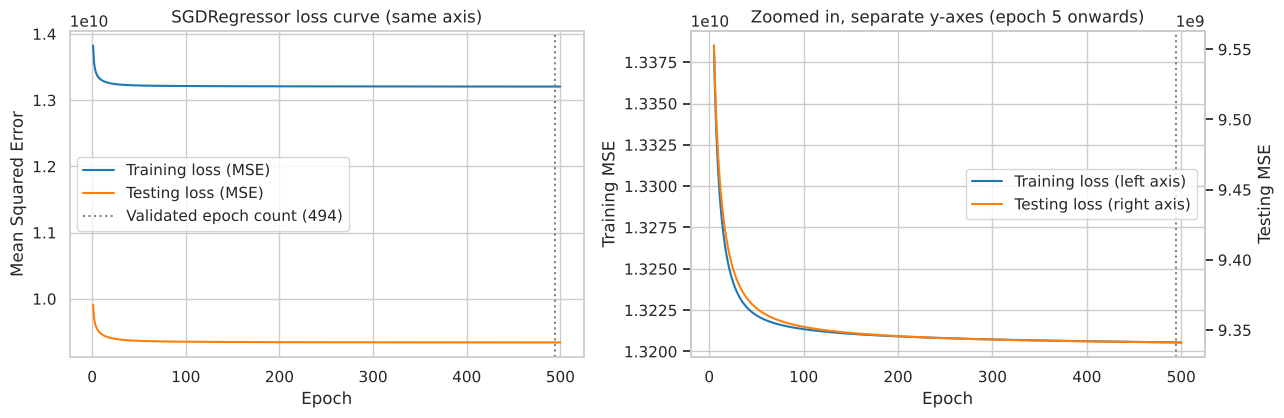

Epoch with the lowest testing MSE: 500 (9,341,160,187)
Change in training MSE between epoch 494 and epoch 500: -0.0003%


In [34]:
# Required loss curve: training and testing MSE per epoch on the same chart (left panel)
epochs = np.arange(1, PLOT_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, train_mse_per_epoch, label="Training loss (MSE)", color="tab:blue")
axes[0].plot(epochs, test_mse_per_epoch, label="Testing loss (MSE)", color="tab:orange")
axes[0].axvline(SGD_EPOCHS, color="grey", linestyle=":", label=f"Validated epoch count ({SGD_EPOCHS})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].set_title("SGDRegressor loss curve (same axis)")
axes[0].legend()

# Right panel: zoom from epoch 5 with a separate y-axis per curve, so small changes become visible
ax_train = axes[1]
ax_test = ax_train.twinx()
line_train = ax_train.plot(epochs[4:], train_mse_per_epoch[4:], color="tab:blue", label="Training loss (left axis)")
line_test = ax_test.plot(epochs[4:], test_mse_per_epoch[4:], color="tab:orange", label="Testing loss (right axis)")
ax_train.axvline(SGD_EPOCHS, color="grey", linestyle=":")
ax_train.set_xlabel("Epoch")
ax_train.set_ylabel("Training MSE")
ax_test.set_ylabel("Testing MSE")
ax_test.grid(False)
ax_train.set_title("Zoomed in, separate y-axes (epoch 5 onwards)")
ax_train.legend(line_train + line_test, [l.get_label() for l in line_train + line_test], loc="center right")
plt.tight_layout()
plt.show()

best_test_epoch = int(np.argmin(test_mse_per_epoch)) + 1
print(f"Epoch with the lowest testing MSE: {best_test_epoch} ({min(test_mse_per_epoch):,.0f})")
print(f"Change in training MSE between epoch {SGD_EPOCHS} and epoch {PLOT_EPOCHS}: "
      f"{(train_mse_per_epoch[-1] / train_mse_per_epoch[SGD_EPOCHS - 1] - 1):.4%}")

**What the plot shows.**

Training MSE falls from about 13.82 billion at epoch 1 to about 13.21 billion at epoch 494, and testing MSE falls from about 9.91 billion to about 9.34 billion. Most of the drop happens in the first 50 to 100 epochs and after that both curves are nearly flat. The right-hand panel zooms in with a separate y-axis for each curve so the small late changes can be seen.

**Interpretation.**

The curves are flat at the end (training MSE changed by about 0.0003% between epoch 494 and 500) and the testing loss never goes back up, so I would say the model has converged and is not overfitting while it trains. It also means the exact epoch matters very little. The testing loss sits below the training loss the whole way. That is not a leak: the test set has a smaller spread than the training set (standard deviation 119,428 against 136,155 RWF) and its biggest income is 2,261,000 against 5,000,000 in training, and MSE reacts strongly to those extreme values.

In [35]:
# The SGD model used in the final comparison is the one at the validated epoch count
sgd_pipeline = Pipeline([("preprocessor", preprocessor), ("model", snapshot_at_chosen_epoch)])
print("SGD pipeline MSE (train):", f"{mse(sgd_pipeline, X_train, y_train):,.0f}")
print("SGD pipeline MSE (test) :", f"{mse(sgd_pipeline, X_test, y_test):,.0f}")

SGD pipeline MSE (train): 13,205,495,540
SGD pipeline MSE (test) : 9,341,198,578


## 11. LinearRegression (closed-form)
`LinearRegression` solves ordinary least squares directly with linear algebra, so there is no learning rate, no epochs and no randomness. It works out in one step the coefficients that give the smallest squared error on the training data.

| | `SGDRegressor` | `LinearRegression` |
|---|---|---|
| Method | Iterative gradient descent | Exact closed-form solution |
| Hyperparameters | Learning rate, `alpha`, epochs | None |
| Regularisation | L2 penalty via `alpha` | None |
| Result | Approximation that depends on the settings | The least-squares optimum for the training data |

Both fit the same kind of straight-line relationship. The closed-form answer is what the gradient descent model is trying to reach.

In [36]:
lr_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", LinearRegression())])
lr_pipeline.fit(X_train, y_train)
print("LinearRegression MSE (train):", f"{mse(lr_pipeline, X_train, y_train):,.0f}")
print("LinearRegression MSE (test) :", f"{mse(lr_pipeline, X_test, y_test):,.0f}")

LinearRegression MSE (train): 13,199,752,840
LinearRegression MSE (test) : 9,334,067,731


The closed-form model gets the lowest possible training MSE for a linear model (13.200 billion, just under SGD's 13.205 billion), which is what you expect from an exact least squares solution. On the test set it is also very slightly better, 9.334 billion against 9.341 billion for SGD, a gap of about 0.08%. So the two implementations are basically the same model. That is a useful check that my gradient descent version converged to the least squares answer. I would not read the tiny gap as one of them being better.

## 12. DecisionTreeRegressor
A decision tree asks a series of yes/no questions (for example *is the occupation elementary?* then *are the usual hours above 40?*) that sort young employees into groups, and predicts the average income of the group a person ends up in. That lets it pick up non-linear effects and interactions that a straight line cannot.

If a tree is allowed to grow without limits it ends up with groups of one or two people, which means it memorises the training data. Three settings keep it in check:
- `max_depth`: how many questions in a row.
- `min_samples_split`: how many people a group needs before it can be split.
- `min_samples_leaf`: the smallest group allowed at the end.

I tune them with 5-fold cross-validation on the training set only. The preprocessing is inside the pipeline, so it is refitted inside every fold.

In [37]:
dt_search = GridSearchCV(
    Pipeline([("preprocessor", build_preprocessor()),
              ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    param_grid={"model__max_depth": [3, 5, 8, 12, None],
                "model__min_samples_split": [2, 10, 50, 100],
                "model__min_samples_leaf": [1, 5, 20, 50]},
    scoring="neg_mean_squared_error", cv=5, n_jobs=-1,
)
dt_search.fit(X_train, y_train)
dt_pipeline = dt_search.best_estimator_

print("Best parameters:", dt_search.best_params_)
print("Cross-validated MSE:", f"{-dt_search.best_score_:,.0f}")
print("DecisionTree MSE (train):", f"{mse(dt_pipeline, X_train, y_train):,.0f}")
print("DecisionTree MSE (test) :", f"{mse(dt_pipeline, X_test, y_test):,.0f}")

Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__min_samples_split': 100}
Cross-validated MSE: 13,182,010,128
DecisionTree MSE (train): 12,028,706,012
DecisionTree MSE (test) : 8,875,347,025


Cross-validation picked a shallow tree: `max_depth = 5`, `min_samples_leaf = 5` and `min_samples_split = 100`, which gives at most 32 groups. The split value of 100 is the biggest one in my grid, so a larger value might do slightly better. The tree has a training MSE of 12.03 billion, a cross-validated MSE of 13.18 billion and a test MSE of 8.88 billion (test R-squared 0.38). It is second best on the test set, about 2% behind the random forest. A single tree is not very stable, because a few high earners inside one group can change its prediction a lot.

## 13. RandomForestRegressor
A random forest builds many decision trees, each on a random resample of the training rows with some randomness in the splits, and averages their predictions. Averaging many different trees cancels out a lot of the overfitting of a single tree. I tune `n_estimators`, `max_depth`, `min_samples_split` and `min_samples_leaf` with 3-fold cross-validation on the training set, with a fixed `random_state`.

In [38]:
rf_search = GridSearchCV(
    Pipeline([("preprocessor", build_preprocessor()),
              ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid={"model__n_estimators": [100, 200, 300],
                "model__max_depth": [8, None],
                "model__min_samples_split": [2, 10],
                "model__min_samples_leaf": [1, 5, 10]},
    scoring="neg_mean_squared_error", cv=3, n_jobs=1,
)
rf_search.fit(X_train, y_train)
rf_pipeline = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print("Cross-validated MSE:", f"{-rf_search.best_score_:,.0f}")
print("RandomForest MSE (train):", f"{mse(rf_pipeline, X_train, y_train):,.0f}")
print("RandomForest MSE (test) :", f"{mse(rf_pipeline, X_test, y_test):,.0f}")

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Cross-validated MSE: 12,878,247,518
RandomForest MSE (train): 10,427,470,815
RandomForest MSE (test) : 8,703,016,614


Cross-validation chose 100 trees with no depth limit, `min_samples_leaf = 10` and `min_samples_split = 2`. Making every final group hold at least 10 people stops the trees from memorising single rows, so the training MSE (10.43 billion) is not far below the cross-validated MSE (12.88 billion) or the test MSE (8.70 billion). Averaging many trees gives the lowest test MSE of the four models (R-squared 0.39) and also the lowest typical error (MAE about 35,900 RWF).

## 14. Model comparison
All four models are tested on exactly the same training and testing rows. Mean Squared Error (MSE) is the average of the squared differences between the actual and predicted earnings. Its unit is RWF squared, so the numbers are huge and hard to picture. RMSE and MAE give the same information in plain RWF. Because MSE squares each error, it reacts strongly to the few very high earners.

In [39]:
fitted_pipelines = {
    "SGDRegressor": sgd_pipeline,
    "LinearRegression": lr_pipeline,
    "DecisionTreeRegressor": dt_pipeline,
    "RandomForestRegressor": rf_pipeline,
}

comparison = pd.DataFrame({
    name: {"Training MSE": mse(p, X_train, y_train), "Testing MSE": mse(p, X_test, y_test)}
    for name, p in fitted_pipelines.items()
}).T
comparison["Test / Train MSE ratio"] = comparison["Testing MSE"] / comparison["Training MSE"]
comparison.index.name = "Model"

display(comparison.style.format({"Training MSE": "{:,.0f}", "Testing MSE": "{:,.0f}", "Test / Train MSE ratio": "{:.2f}"}))

,Training MSE,Testing MSE,Test / Train MSE ratio
Model,,,
SGDRegressor,"13,205,495,540","9,341,198,578",0.71
LinearRegression,"13,199,752,840","9,334,067,731",0.71
DecisionTreeRegressor,"12,028,706,012","8,875,347,025",0.74
RandomForestRegressor,"10,427,470,815","8,703,016,614",0.83


In [40]:
# The same models in plain RWF units (supplementary; the assignment metric is MSE)
supplementary = pd.DataFrame({
    name: {"Test RMSE (RWF)": np.sqrt(mse(p, X_test, y_test)),
           "Test MAE (RWF)": mean_absolute_error(y_test, p.predict(X_test)),
           "Test R-squared": r2_score(y_test, p.predict(X_test))}
    for name, p in fitted_pipelines.items()
}).T
print(f"For reference, the standard deviation of test earnings is {y_test.std():,.0f} RWF "
      f"and the median is {y_test.median():,.0f} RWF.")
display(supplementary.style.format({"Test RMSE (RWF)": "{:,.0f}", "Test MAE (RWF)": "{:,.0f}", "Test R-squared": "{:.3f}"}))

For reference, the standard deviation of test earnings is 119,428 RWF and the median is 39,000 RWF.


,Test RMSE (RWF),Test MAE (RWF),Test R-squared
SGDRegressor,"96,650","38,733",0.345
LinearRegression,"96,613","38,122",0.345
DecisionTreeRegressor,"94,209","37,287",0.377
RandomForestRegressor,"93,290","35,886",0.390


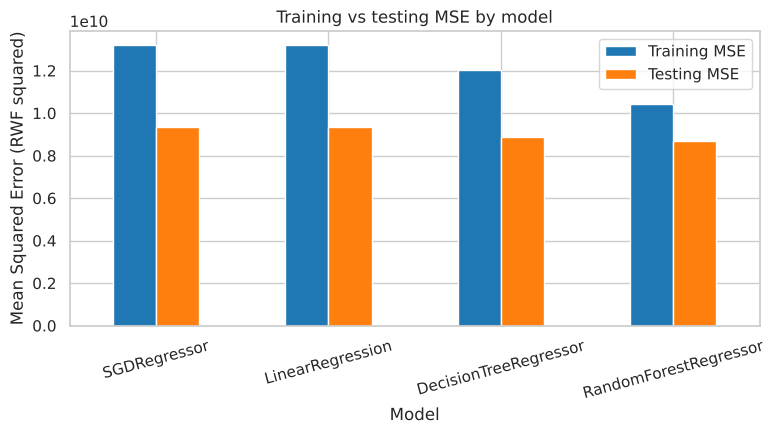

In [41]:
# Visual comparison of training and testing MSE
comparison[["Training MSE", "Testing MSE"]].plot(kind="bar", figsize=(8, 4.5), color=["tab:blue", "tab:orange"])
plt.ylabel("Mean Squared Error (RWF squared)")
plt.title("Training vs testing MSE by model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Reading the table.**
- **Test MSE is lower than training MSE for every model** (ratios 0.71 to 0.83). I do not see classic overfitting for any model, where the test error would be higher than the training error. This also does not mean the models are unusually good: the test set has fewer extreme earners than the training set, so it is the easier set to predict. The cross-validation further down gives errors of about 12 to 13 billion, which is more realistic for new people.
- **Linear models** have the highest test MSE (about 9.33 to 9.34 billion), an RMSE of about 96,600 RWF and an R-squared of 0.345. A straight line cannot capture much of how pay depends on job and education together.
- **Decision tree** is second, with 8.88 billion (RMSE about 94,200, R-squared 0.377).
- **Random forest** is lowest, with 8.70 billion (RMSE about 93,300, R-squared 0.39), and it also has the smallest typical error: an MAE of about 35,900 RWF against about 37,300 for the tree and 38,100 to 38,700 for the linear models.

**MSE and outliers.**

For the random forest, the 22 biggest squared errors (the top 1% of test rows) make up 66% of its total test squared error, and the 10 biggest make up 51%. So MSE mostly shows how well the model copes with a few high earners. The MAE says the typical error is about 36,000 RWF, which is close to the median income of 39,000, so the predictions are rough.

In [42]:
# How much of the best model's test MSE comes from a handful of extreme errors?
best_by_mse = comparison["Testing MSE"].idxmin()
squared_errors = (y_test - fitted_pipelines[best_by_mse].predict(X_test)) ** 2
n_top = max(1, int(0.01 * len(squared_errors)))
print(f"{best_by_mse}: the largest {n_top} squared errors (top 1% of test rows) account for "
      f"{squared_errors.nlargest(n_top).sum() / squared_errors.sum():.0%} of the total test squared error.")
print(f"The largest 10 account for {squared_errors.nlargest(10).sum() / squared_errors.sum():.0%}.")

RandomForestRegressor: the largest 22 squared errors (top 1% of test rows) account for 66% of the total test squared error.
The largest 10 account for 51%.


### Robustness check: household-aware split
The survey interviews whole households, so with a plain random split two members of the same household can end up one in training and one in testing, which could make the test results look a bit better than they should. As an extra check (the official comparison stays on the required split), I refit the three models that do not need the epoch loop, with their chosen settings, on a split that keeps every household (PSU, household number and household id together) on one side only.

In [43]:
from sklearn.model_selection import GroupShuffleSplit

households = (df_model.loc[X.index, "psu_no"].astype(str) + "_" + df_model.loc[X.index, "qh_no"].astype(str) + "_" + df_model.loc[X.index, "hhid"].astype(str))
group_train_idx, group_test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE).split(X, y, households))
Xg_train, Xg_test = X.iloc[group_train_idx], X.iloc[group_test_idx]
yg_train, yg_test = y.iloc[group_train_idx], y.iloc[group_test_idx]
print("Households shared between train and test:", len(set(households.iloc[group_train_idx]) & set(households.iloc[group_test_idx])))

check_models = {
    "LinearRegression": clone(lr_pipeline),
    "DecisionTreeRegressor": clone(dt_pipeline),          # clone keeps the tuned settings, drops the fitted state
    "RandomForestRegressor": clone(rf_pipeline),
}
robustness = pd.DataFrame({
    name: {"Testing MSE, random split": comparison.loc[name, "Testing MSE"],
           "Testing MSE, household split": mse(m.fit(Xg_train, yg_train), Xg_test, yg_test)}
    for name, m in check_models.items()
}).T
display(robustness.style.format("{:,.0f}"))

Households shared between train and test: 0


,"Testing MSE, random split","Testing MSE, household split"
LinearRegression,"9,334,067,731","9,396,347,357"
DecisionTreeRegressor,"8,875,347,025","10,222,536,897"
RandomForestRegressor,"8,703,016,614","8,416,608,708"


### Cross-validation check
One split is not a strong basis for ranking models when a few big earners decide the score. So I also score the same three models with 5-fold cross-validation on all modelled rows, once with ordinary shuffled folds and once with folds that keep households together. The mean and spread across folds show how stable each model's error is. This is only a check: the settings were chosen on the training rows, so these figures are slightly on the optimistic side for the tree and the forest.

In [44]:
from sklearn.model_selection import GroupKFold, KFold, cross_val_score

cv_rows = {}
for name in ["LinearRegression", "DecisionTreeRegressor", "RandomForestRegressor"]:
    estimator = clone(fitted_pipelines[name])
    shuffled = -cross_val_score(estimator, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                                scoring="neg_mean_squared_error")
    grouped = -cross_val_score(estimator, X, y, cv=GroupKFold(n_splits=5), groups=households,
                               scoring="neg_mean_squared_error")
    cv_rows[name] = {"Shuffled 5-fold: mean MSE": shuffled.mean(), "Shuffled 5-fold: std": shuffled.std(),
                     "Household 5-fold: mean MSE": grouped.mean(), "Household 5-fold: std": grouped.std()}
display(pd.DataFrame(cv_rows).T.style.format("{:,.0f}"))

,Shuffled 5-fold: mean MSE,Shuffled 5-fold: std,Household 5-fold: mean MSE,Household 5-fold: std
LinearRegression,"12,602,352,479","3,812,494,036","12,639,553,641","5,246,459,863"
DecisionTreeRegressor,"12,758,413,286","2,919,397,847","12,358,747,891","4,555,509,995"
RandomForestRegressor,"12,122,238,601","2,660,553,659","12,173,141,221","4,562,133,778"


**Household-aware split.**

When I keep whole households together, the random forest still has the lowest test MSE (8.42 billion), then linear regression (9.40 billion) and the tree (10.22 billion). The test rows are different in the two splits, so I do not compare the numbers across the two tables, but the winner is the same.

**Cross-validation.**

With ordinary shuffled folds the mean MSE is 12.12 billion for the forest, 12.60 billion for linear regression and 12.76 billion for the tree. With household folds the three are very close, between 12.17 and 12.64 billion, and the forest is lowest again. The spread between folds (standard deviations from 2.7 to 5.2 billion) is much bigger than the gaps between the models.

**What this means.**

The random forest comes out first on the required split, on the household split and in both cross-validations, but its lead is small compared with how much the score moves from fold to fold. I would not call it clearly better than the others. I also expect the typical error on new people to be nearer the cross-validated 12 to 13 billion (an RMSE of roughly 110,000 RWF) than the 8.70 billion on the required split. The official choice below still uses the required split, as the assignment says.

## 15. Select the best model
My rule is simple: the best model is the one with the lowest testing MSE. The test data was never used for training or tuning, so it is the fairest guide to how a model will do on new young employees. I do not use training MSE alone, because a model can score well on it just by memorising the data.

In [45]:
best_name = comparison["Testing MSE"].idxmin()
best_pipeline = fitted_pipelines[best_name]

print(f"Best model by testing MSE: {best_name}")
print(f"  Training MSE: {comparison.loc[best_name, 'Training MSE']:,.0f}")
print(f"  Testing MSE : {comparison.loc[best_name, 'Testing MSE']:,.0f}")
print()
print("Testing MSE of each model relative to the best (1.00 = best):")
print((comparison["Testing MSE"] / comparison.loc[best_name, "Testing MSE"]).sort_values().round(3).to_string())

Best model by testing MSE: RandomForestRegressor
  Training MSE: 10,427,470,815
  Testing MSE : 8,703,016,614

Testing MSE of each model relative to the best (1.00 = best):
Model
RandomForestRegressor   1.00
DecisionTreeRegressor   1.02
LinearRegression        1.07
SGDRegressor            1.07


**Selection.**

By that rule the best model is the **RandomForestRegressor**, with a training MSE of about 10.43 billion and a testing MSE of about 8.70 billion. The decision tree's test MSE is about 2% higher, and LinearRegression and SGDRegressor are about 7% higher.

**Why it was selected, and its limits.**

I chose it only because it had the lowest test error, not because I expected it to win. It can pick up combinations such as education with occupation and sector, which the linear models cannot, and it has the lowest MAE as well. The limits are that its lead over the decision tree is only about 2% and the cross-validation results are close. It is the model that does best in all three checks (required split, household split, cross-validation), and it is the one I saved for the API.

## 16. Scatter plot before training the line
I find the numerical feature with the strongest correlation with `cash` (the largest absolute Pearson correlation, calculated on the training data) and plot it against monthly earnings.

In [46]:
train_corr = pd.concat([X_train[FEATURES_NUMERICAL], y_train], axis=1).corr()[TARGET].drop(TARGET)
top_feature = train_corr.abs().idxmax()
print("Correlation of each numerical feature with cash (training data):")
print(train_corr.round(3).to_string())
print(f"\nMost strongly correlated numerical feature: {top_feature} (r = {train_corr[top_feature]:.3f})")

Correlation of each numerical feature with cash (training data):
a04       0.15
usual_h   0.09
d24       0.01
d24b      0.07

Most strongly correlated numerical feature: a04 (r = 0.149)


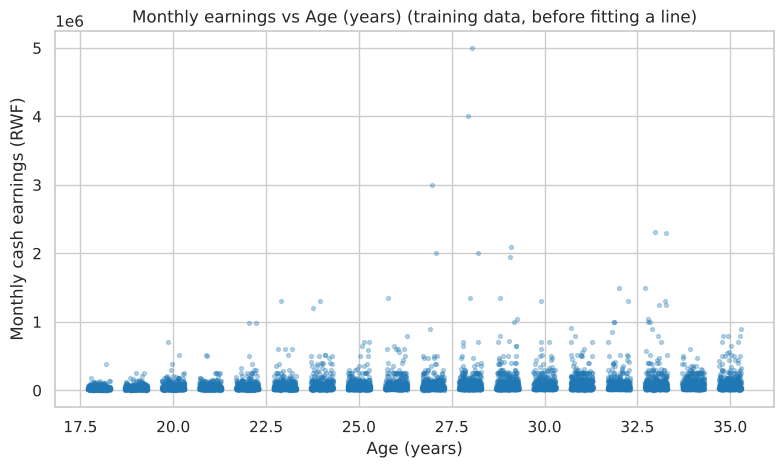

In [47]:
FEATURE_LABELS = {"a04": "Age (years)", "usual_h": "Usual weekly working hours",
                  "d24": "Work experience (years)", "d24b": "Months worked per year"}
feature_label = FEATURE_LABELS[top_feature]

rng = np.random.default_rng(RANDOM_STATE)
jitter = rng.uniform(-0.3, 0.3, size=len(X_train))           # small horizontal jitter so overlapping points are visible

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top_feature] + jitter, y_train, s=8, alpha=0.3, color="tab:blue")
plt.xlabel(feature_label)
plt.ylabel("Monthly cash earnings (RWF)")
plt.title(f"Monthly earnings vs {feature_label} (training data, before fitting a line)")
plt.tight_layout()
plt.show()

**What the plot shows.**

Age is the numerical feature most strongly correlated with earnings (r = 0.149 on the training data), so it is the one plotted. Ages are whole numbers, so each age is a column of points, and I added a small horizontal jitter so the points do not hide each other. Most people earn less than about 250,000 RWF at every age, the top of the cloud rises a little with age, and a few points sit above 1 million.

**Observation and decision.**

The relationship is positive but weak and noisy, which fits the low correlation. Age alone clearly cannot separate low and high earners, which is why the main models use all ten features.

## 17. Scatter plot after training, with the fitted regression line
This is the same scatter plot with a line from a one-feature `LinearRegression` fitted on the selected feature only.

This one-feature model is only there to draw the line on a 2D chart. It is not one of the four models I compare and it does not replace them. The multivariate models use all ten features.

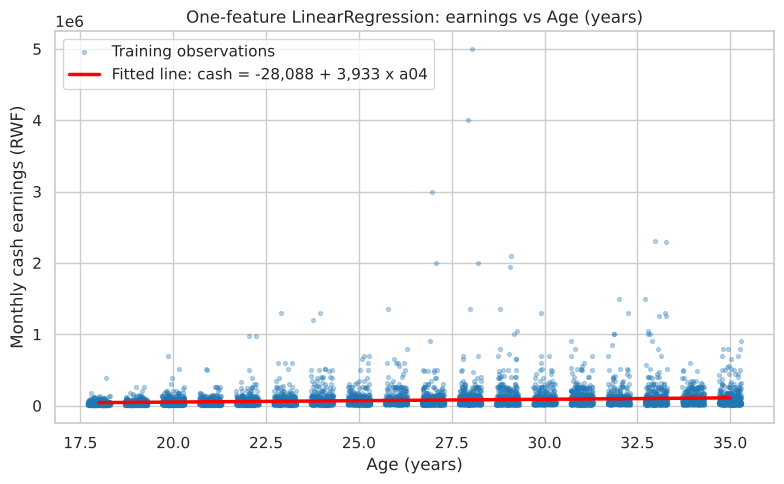

Slope: 3,933 RWF per unit of a04
One-feature model R-squared on training data: 0.022
One-feature model test MSE: 13,782,244,176


In [48]:
# One-feature linear regression, used only for the visualisation
line_model = LinearRegression()
line_model.fit(X_train[[top_feature]], y_train)

x_grid = np.linspace(X_train[top_feature].min(), X_train[top_feature].max(), 100).reshape(-1, 1)
x_grid_df = pd.DataFrame(x_grid, columns=[top_feature])
y_line = line_model.predict(x_grid_df)

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top_feature] + jitter, y_train, s=8, alpha=0.3, color="tab:blue", label="Training observations")
plt.plot(x_grid, y_line, color="red", linewidth=2.5,
         label=f"Fitted line: cash = {line_model.intercept_:,.0f} + {line_model.coef_[0]:,.0f} x {top_feature}")
plt.xlabel(feature_label)
plt.ylabel("Monthly cash earnings (RWF)")
plt.title(f"One-feature LinearRegression: earnings vs {feature_label}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Slope: {line_model.coef_[0]:,.0f} RWF per unit of {top_feature}")
print(f"One-feature model R-squared on training data: {line_model.score(X_train[[top_feature]], y_train):.3f}")
print(f"One-feature model test MSE: {mean_squared_error(y_test, line_model.predict(X_test[[top_feature]])):,.0f}")

**What the plot shows.**

The red line comes from a LinearRegression with age as its only input. It rises by about 3,933 RWF for each extra year of age on average, but the R-squared is only 0.022 and the line stays near the bottom of the cloud, because most employees earn modest amounts.

**Why this is not a replacement for the main models.**

The line model uses one feature and is only there to draw a line on a 2D plot. Its test MSE (about 13.78 billion) is worse than every multivariate model (8.70 to 9.34 billion), so I do need all the features. The slope is an average pattern in the survey and does not mean that getting older causes higher pay.

## 18. Save the best model
I save the best model with joblib as one scikit-learn `Pipeline` that holds the fitted preprocessing and the fitted model. It takes raw feature values (text categories, unscaled numbers, blanks) and does the imputing, encoding and scaling itself. I also write a small JSON file with the feature names and allowed category values, to help with the API and the app. Then I reload the file and check that it gives the same predictions as the model in memory.

In [49]:
MODEL_PATH = "best_model.joblib"
joblib.dump(best_pipeline, MODEL_PATH, compress=3)   # compress=3 keeps the file small; loading is unchanged

# Metadata to help the future API (input names, categories, versions); not needed to load the model
metadata = {
    "best_model": best_name,
    "target": TARGET,
    "target_unit": "RWF per month",
    "numerical_features": FEATURES_NUMERICAL,
    "categorical_features": FEATURES_CATEGORICAL,
    "categorical_values": {c: sorted(X_train[c].dropna().unique().tolist()) for c in FEATURES_CATEGORICAL},
    "numerical_ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in FEATURES_NUMERICAL},
    "sklearn_version": sklearn.__version__,
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved:", MODEL_PATH, f"({Path(MODEL_PATH).stat().st_size / 1e3:,.0f} KB) and model_metadata.json")

Saved: best_model.joblib (2,097 KB) and model_metadata.json


In [50]:
# Test the saved pipeline BEFORE trusting it: reload it and confirm it gives the same predictions as the in-memory model
reloaded = joblib.load(MODEL_PATH)
same_predictions = np.allclose(reloaded.predict(X_test), best_pipeline.predict(X_test))
print("Reloaded pipeline steps:", [name for name, _ in reloaded.steps])
print("Reloaded pipeline reproduces in-memory predictions on all test rows:", same_predictions)
print("Reloaded pipeline test MSE:", f"{mse(reloaded, X_test, y_test):,.0f}")
assert same_predictions

Reloaded pipeline steps: ['preprocessor', 'model']
Reloaded pipeline reproduces in-memory predictions on all test rows: True
Reloaded pipeline test MSE: 8,703,016,614


In [51]:
# Colab only: download the saved files to your computer (skipped automatically elsewhere)
try:
    from google.colab import files
    files.download(MODEL_PATH)
    files.download("model_metadata.json")
except ImportError:
    print("Not running in Colab; files are in the current folder.")

### Export for the API
This cell saves the pipeline together with the training rows in `best_model.pkl`. The API needs the rows because a random forest cannot learn from new data on its own, so when someone uploads a CSV to `/retrain` it is refitted on the old rows plus the new ones. The file goes into the `API` folder of the repository, and in Colab it is also downloaded.

In [52]:
train_rows = X_train.copy()
train_rows[TARGET] = y_train

api_bundle = {
    "pipeline": best_pipeline,
    "training_data": {c: train_rows[c].tolist() for c in train_rows.columns},
    "info": {"model_name": best_name, "sklearn_version": sklearn.__version__},
}
joblib.dump(api_bundle, "best_model.pkl", compress=3)

from google.colab import files
files.download("best_model.pkl")

## 19. Reusable prediction function
`predict_monthly_income()` loads the saved pipeline (once, then it keeps it in memory), takes one person as a dictionary, a one-row DataFrame or a Series, checks that every required feature is there, and returns the predicted monthly earnings in RWF. I wrote it so the API can use it as it is. A linear model can sometimes give a negative number and pay cannot be negative, so the result is floored at 0.

In [53]:
_MODEL_CACHE = {}

def load_income_model(model_path=MODEL_PATH):
    """Load the saved pipeline from disk the first time and reuse it afterwards."""
    if model_path not in _MODEL_CACHE:
        _MODEL_CACHE[model_path] = joblib.load(model_path)
    return _MODEL_CACHE[model_path]

def predict_monthly_income(observation, model_path=MODEL_PATH):
    """
    Predict monthly cash earnings (RWF) for ONE young employee.

    observation: dict, pandas Series, or one-row DataFrame with these raw columns:
        a04, usual_h, d24, d24b (numbers) and a01, b02a, indd01, main_sect, prod_unit, d08 (text).
        A blank (None or NaN) is allowed for any value; the pipeline handles it.
    Returns: predicted income as a float in RWF.
    """
    if isinstance(observation, dict):
        row = pd.DataFrame([observation])
    elif isinstance(observation, pd.Series):
        row = observation.to_frame().T
    elif isinstance(observation, pd.DataFrame):
        row = observation.copy()
    else:
        raise TypeError("observation must be a dict, pandas Series or one-row DataFrame")

    if len(row) != 1:
        raise ValueError(f"Exactly one observation is expected, got {len(row)}")
    missing_columns = [c for c in FEATURES if c not in row.columns]
    if missing_columns:
        raise ValueError(f"Missing required input features: {missing_columns}")

    row = row[FEATURES].copy()
    for column in FEATURES_NUMERICAL:                       # make sure numbers are numeric
        row[column] = pd.to_numeric(row[column], errors="coerce")
    for column in FEATURES_CATEGORICAL:                     # None -> NaN so the imputer can handle it
        row[column] = row[column].astype(object).where(row[column].notna(), np.nan)

    prediction = float(load_income_model(model_path).predict(row)[0])
    return max(prediction, 0.0)

### Demonstration on one real test observation
I use the first row of the test set. Nothing here is typed in or made up.

In [54]:
test_row = X_test.iloc[[0]]                                  # one actual row from the test set
actual_income = float(y_test.iloc[0])
print("Input features of the test observation:")
print(test_row.iloc[0].to_string())
print()

predicted_income = predict_monthly_income(test_row.iloc[0].to_dict())   # raw values only, no manual encoding
demo = pd.DataFrame({"Result": [actual_income, predicted_income, abs(actual_income - predicted_income)]},
                    index=["Actual monthly income (RWF)", "Predicted monthly income (RWF)", "Absolute prediction difference (RWF)"])
display(demo.style.format("{:,.0f}"))

Input features of the test observation:
a04                                29
usual_h                          6.00
d24                             15.00
d24b                            12.00
a01                              Male
b02a                Primary education
indd01         Elementary_occupations
main_sect                    Services
prod_unit             Informal Sector
d08          Daily contract/Agreement



,Result
Actual monthly income (RWF),"39,000"
Predicted monthly income (RWF),"53,936"
Absolute prediction difference (RWF),"14,936"


In [55]:
# Safety checks for reuse in the API: the function matches the pipeline, and blanks do not crash it
assert np.isclose(predicted_income, max(best_pipeline.predict(test_row)[0], 0.0))
example_with_blanks = test_row.iloc[0].to_dict()
example_with_blanks.update({"d08": None, "b02a": None})
print("Prediction with two blank categorical values:", f"{predict_monthly_income(example_with_blanks):,.0f} RWF")
unseen_category = test_row.iloc[0].to_dict() | {"indd01": "A category never seen in training"}
print("Prediction with an unseen category         :", f"{predict_monthly_income(unseen_category):,.0f} RWF")

Prediction with two blank categorical values: 53,689 RWF
Prediction with an unseen category         : 162,107 RWF


**What this demonstrates.**

The function takes the raw values of a real person from the test set (a 29-year-old man who works 6 hours a week, has 15 years of experience, works 12 months a year, and has primary education, an elementary occupation, services, the informal sector and a daily contract) and returns an estimate in RWF, with no manual encoding or scaling. His actual income is 39,000 RWF and the model predicts about 53,900, so it is off by about 14,900 RWF. That is one example and not a measure of accuracy: the RMSE and MAE from earlier (about 93,300 and 35,900 RWF) are the better guide.

The checks below it show that blank values do not break the function (about 53,700 RWF with education and contract left blank). A category the model never saw gives a very different answer (about 162,100 RWF), because every occupation column is then switched off, a pattern the forest never saw in training. For the API this means only known category labels should be accepted, and that is how I built it.

## 20. Final conclusion

In [56]:
print(f"Population modelled : {len(df_model):,} young employees aged 18-35 ({len(X_train):,} train / {len(X_test):,} test)")
print(f"Target              : cash, monthly cash earnings in RWF (median {y.median():,.0f}, mean {y.mean():,.0f})")
print(f"Features ({len(FEATURES)})        : {', '.join(FEATURES)}")
print()
display(comparison[["Training MSE", "Testing MSE"]].style.format("{:,.0f}"))
print(f"Best model: {best_name} | testing MSE {comparison.loc[best_name, 'Testing MSE']:,.0f} "
      f"(RMSE about {np.sqrt(comparison.loc[best_name, 'Testing MSE']):,.0f} RWF)")

Population modelled : 11,232 young employees aged 18-35 (8,985 train / 2,247 test)
Target              : cash, monthly cash earnings in RWF (median 39,000, mean 74,877)
Features (10)        : a04, usual_h, d24, d24b, a01, b02a, indd01, main_sect, prod_unit, d08



,Training MSE,Testing MSE
Model,,
SGDRegressor,"13,205,495,540","9,341,198,578"
LinearRegression,"13,199,752,840","9,334,067,731"
DecisionTreeRegressor,"12,028,706,012","8,875,347,025"
RandomForestRegressor,"10,427,470,815","8,703,016,614"


Best model: RandomForestRegressor | testing MSE 8,703,016,614 (RMSE about 93,290 RWF)


### Summary

**Problem and mission.** Young people looking for work often do not know what they could earn. My mission is to build technology that helps young Africans find income opportunities, and this project does a small part of that by estimating the monthly cash earnings of a young employed person in Rwanda from their profile.

**Data and target.** I used the Rwanda Labour Force Survey 2025 microdata from NISR. The target is `cash`, monthly cash income for employees in RWF. After filtering to employees aged 18 to 35 with an income value I had 11,232 people, split into 8,985 for training and 2,247 for testing. Missing income was never replaced by zero.

**Features and models.** I used ten features (age, gender, education, occupation, industry, usual hours, experience, months worked, formal or informal sector, and contract duration), with imputing, scaling and one-hot encoding fitted on the training data only. I compared `SGDRegressor`, `LinearRegression`, `DecisionTreeRegressor` and `RandomForestRegressor` on the same stratified split using MSE.

**Result.** The `RandomForestRegressor` had the lowest test MSE, about 8.70 billion (RMSE about 93,300 RWF), so it is the model I saved as `best_model.joblib`. The two linear models ended up almost identical (about 9.33 to 9.34 billion), which shows the gradient descent version converged, and the decision tree was close behind the forest (8.88 billion). The cross-validation and household checks say the forest's lead is small and that errors on new data will probably be bigger than on this test set.

**Usefulness.** The pipeline gives a data-based starting estimate of pay for a young employee with a given profile, and it takes raw inputs, so the API and the mobile app can use it directly.

**Limitations.**
- It only covers young employees in this survey. It is not a model of freelancer or self-employed income and it cannot promise anyone a salary.
- The data is from one year (2025), so it does not follow pay changes or inflation.
- A few very high earners dominate the error, and a typical estimate is still off by about 36,000 RWF (MAE).
- Household members can be similar to each other, and the models are hard to tell apart in cross-validation.
- Differences between groups, such as men and women, are patterns in the data and not causes.

**Possible improvements.** Add location (province, urban or rural), predict a range instead of one number, try the log of income to reduce the pull of extreme values, and use cross-validation that keeps households together when choosing the model.